In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
filename = "G:/neural_network_from_scratch/bank marketing/bank-additional.csv"
df = pd.read_csv(filename,sep=";")
df.head(1)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no


In [4]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [5]:
df_2 = df.drop(columns=['age','campaign','marital','education','month','day_of_week','housing', 'loan','duration'],axis=1)

In [6]:
df_2.columns

Index(['job', 'default', 'contact', 'pdays', 'previous', 'poutcome',
       'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m',
       'nr.employed', 'y'],
      dtype='object')

In [7]:
df_2['previously_contacted'] = (df_2['pdays'] != 999).astype(int)
df_2['pdays_actual'] = df_2['pdays'].replace(999, np.nan)
df_2['pdays_actual'] = df_2['pdays_actual'].fillna(0)
df_2.drop(columns=['pdays'], inplace=True)

In [8]:
categorical_features = [
    "job",
    "default",
    "contact",
    "poutcome",
    "y"
]

df_enc = pd.get_dummies(df_2,columns=categorical_features,dtype=int)
df_enc.head()

,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,previously_contacted,pdays_actual,job_admin.,job_blue-collar,...,default_no,default_unknown,default_yes,contact_cellular,contact_telephone,poutcome_failure,poutcome_nonexistent,poutcome_success,y_no,y_yes
0,0,-1.8,92.893,-46.2,1.313,5099.1,0,0.0,0,1,...,1,0,0,1,0,0,1,0,1,0
1,0,1.1,93.994,-36.4,4.855,5191.0,0,0.0,0,0,...,1,0,0,0,1,0,1,0,1,0
2,0,1.4,94.465,-41.8,4.962,5228.1,0,0.0,0,0,...,1,0,0,0,1,0,1,0,1,0
3,0,1.4,94.465,-41.8,4.959,5228.1,0,0.0,0,0,...,1,0,0,0,1,0,1,0,1,0
4,0,-0.1,93.200,-42.0,4.191,5195.8,0,0.0,1,0,...,1,0,0,1,0,0,1,0,1,0


In [9]:
X = df_enc.copy().drop(columns=["y_no","y_yes"],axis=1)
y = df_enc['y_yes'].values.reshape(-1,1)

print(X.shape)
print(y.shape)

(4119, 28)
(4119, 1)


In [10]:
model_v1 = np.load("G:/neural_network_from_scratch/bank marketing/model_v1.npz")

In [14]:
mean = model_v1['mean']
std = model_v1['std']

w1 = model_v1['w1']
b1 = model_v1['b1']
w2 = model_v1['w2']
b2 = model_v1['b2']
w3 = model_v1['w3']
b3 = model_v1['b3']

In [20]:
continuous_cols = ['previous','pdays_actual','emp.var.rate','cons.price.idx','cons.conf.idx', 'euribor3m', 'nr.employed']

X[continuous_cols] = (X[continuous_cols] - mean) / std

In [21]:
def Relu(z):
    return np.maximum(0,z)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

In [22]:
y_pred = []

In [25]:
def yes_prob(X):
    z1 = np.dot(X,w1) + b1
    a1 = Relu(z1)

    z2 = np.dot(a1,w2) + b2
    a2 = Relu(z2)

    z3 = np.dot(a2,w3) + b3
    a3 = sigmoid(z3)

    if (a3>=0.3):
        y_pred.append("yes") 
    else:
        y_pred.append("no")

In [28]:
for index,row in X.iterrows():
    yes_prob(row)

In [30]:
df['y_pred'] = y_pred

In [38]:
predictions = df.groupby(['y','y_pred']).size().reset_index(name="count")

In [39]:
predictions

,y,y_pred,count
0,no,no,3433
1,no,yes,235
2,yes,no,219
3,yes,yes,232


In [41]:
cm = predictions.pivot(
    index='y',
    columns='y_pred',
    values='count'
).fillna(0)

print(cm)

y_pred    no  yes
y                
no      3433  235
yes      219  232


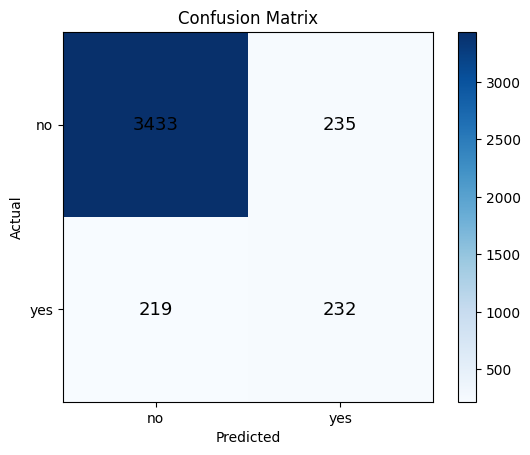

In [42]:
plt.imshow(cm.values, cmap='Blues')

plt.colorbar()

plt.xticks(range(len(cm.columns)), cm.columns)
plt.yticks(range(len(cm.index)), cm.index)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, int(cm.iloc[i, j]),
                 ha='center', va='center',
                 fontsize=13)

plt.show()